# Model 1 results: what drives a country's CO2 emissions?

Shows the results of `src/models/train_m1_emissions.py` in graphs and plain words.
Run the training script first; it saves everything to `reports/models/m1/` and logs the same files to the MLflow session run (Artifacts > comparison).

**The question:** when a country's population and income per person change, how much do its emissions change?

In [2]:
import json, os
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

root = Path.cwd()
while not (root / "dvc.yaml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
R = Path("reports/models/m1")
res = pd.read_csv(R / "comparison.csv")
summary = json.loads((R / "summary.json").read_text())
display(Markdown(f"**Champion:** `{summary['champion']}`  \n**Rule:** {summary['rule']}  \n**Decision:** {summary['reason']}"))

**Champion:** `growth_linear_5yr`  
**Rule:** challenger needs average skill > reference + 5 points and must win at least 2 of 3 exams  
**Decision:** No challenger passes the rule, so growth_linear_5yr stays. growth_gbm: -12.5 pts, wins 1/3 -> fails; growth_avg_linear_gbm: -2.1 pts, wins 1/3 -> fails; growth_linear_plus_gbm_fix: -11.1 pts, wins 1/3 -> fails

## The models, in plain words

### How the growth models work
Each growth model learns a rule like

> % change in emissions = a × % change in population + b × % change in income per person + drift × years

and predicts a future year by starting from the country's **last known emissions** and growing them by that rule.

**Worked example** (round made-up numbers): with a = 1.32, b = 0.56, drift = −0.4%/year, if a country's population grows 12% and income per person 55% over 10 years, emissions grow by about 1.32 × 11.3% + 0.56 × 43.8% − 0.4% × 10 ≈ 35.5% in log terms, i.e. **about 1.42 × the starting level**. (11.3% and 43.8% are the log versions of +12% and +55%.)

In [3]:
desc = pd.Series(summary["descriptions"], name="what it is").to_frame()
desc.index.name = "model"
pd.set_option("display.max_colwidth", None)
desc

,what it is
model,
baseline_stays_same,Baseline. Each country's emissions stay at their last known level. Every model must beat this.
baseline_global_average,Baseline (floor). One average emissions value for every country.
level_pop_income,Predicts emissions directly from population and income per person (logs). Explains differences BETWEEN countries; does not use a country's own history.
level_pop_income_energy,"Same as level_pop_income plus energy used per unit of GDP. Scores high mostly because population x income x energy-per-GDP = total energy, and CO2 follows energy almost by accounting."
growth_linear_1yr,Linear rule learned from 1-year changes: % change in emissions = a x % change in population + b x % change in income + drift x years. Predicts from each country's last known emissions.
growth_linear_5yr,"Same linear rule, learned from 5-year changes (less year-to-year noise). Reference model for the champion rule."
growth_gbm,"Gradient boosting (many small decision trees) learning how emissions change from population change, income change, number of years and the country's income level, so it can learn that rich and poor countries react differently."
growth_avg_linear_gbm,Average of growth_linear_5yr and growth_gbm predictions.
growth_linear_plus_gbm_fix,growth_linear_5yr first; then a small gradient-boosting model learns only the linear rule's typical mistakes and corrects them.


## How to read the scores

| Word | Plain meaning |
|---|---|
| **Stays the same** | The simplest guess: each country's emissions stay at their last known level. Every model must beat it. |
| **Skill vs stays the same** | How much smaller a model's error is than "stays the same". **+26% = about a quarter smaller.** Below 0 = worse than "stays the same". |
| **Exam** | Train only on years up to 1990, 2000 or 2010, then predict the next 12 years. Three exams show the model is not lucky once. |
| **Change R²** | The share of the real rise or fall in emissions the model explains. 0.40 = 40%. "Stays the same" always explains 0. |
| **a, b, drift** | The learned rule (see above). Drift below 0 = countries slowly getting cleaner per unit of income. |

In [4]:
growth = res[res.model.str.startswith("growth")]
table = growth.pivot(index="model", columns="exam", values="skill_vs_stays_same_pct").round(1)
table.columns = [f"skill % (predict {c+1}-{c+12})" for c in table.columns]
table["average skill %"] = table.mean(axis=1).round(1)
table["change R² (2011-2022)"] = growth[growth.exam == 2010].set_index("model")["change_r2"].round(2)
table.sort_values("average skill %", ascending=False)

,skill % (predict 1991-2002),skill % (predict 2001-2012),skill % (predict 2011-2022),average skill %,change R² (2011-2022)
model,,,,,
growth_linear_1yr,30.2,31.2,18.1,26.5,0.22
growth_linear_5yr,31.2,18.6,28.2,26.0,0.40
growth_avg_linear_gbm,27.3,13.5,30.8,23.9,0.45
growth_linear_plus_gbm_fix,19.3,-5.8,31.1,14.9,0.45
growth_gbm,14.7,-4.4,30.1,13.5,0.43


## Graph 1: skill in each exam

**How to read it:** each group of bars is one exam. The number on each bar is the skill. Above the black line = the model beat "stays the same".

**What to look for:** a reliable model stays clearly above 0 in **all three** exams.

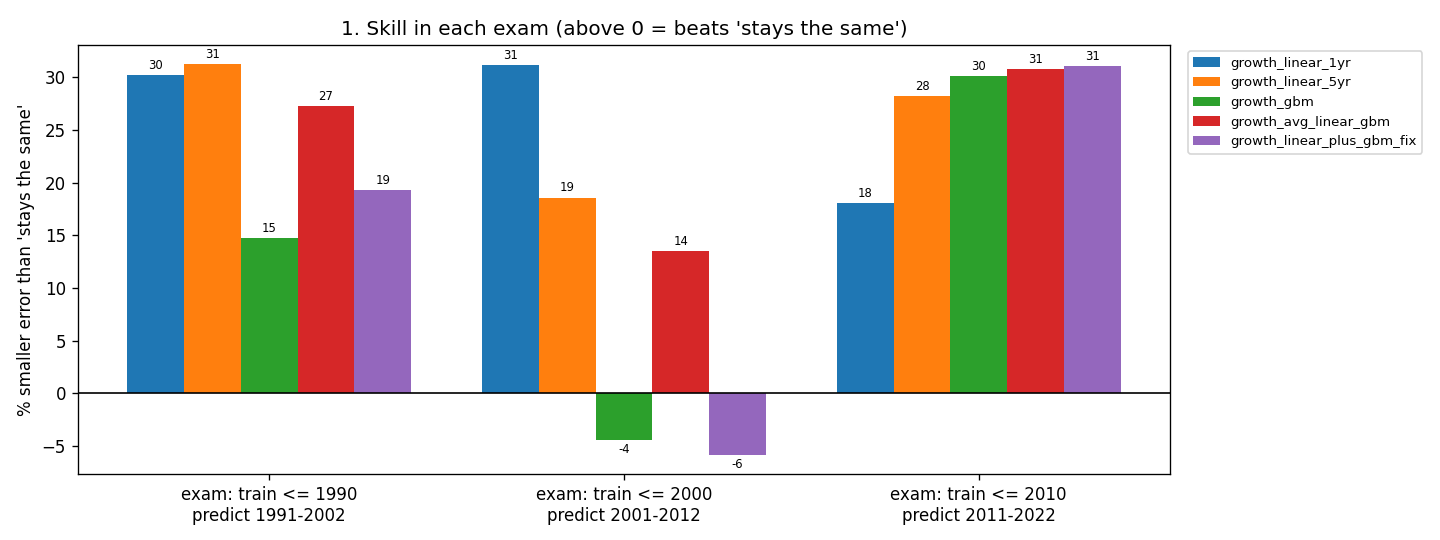

In [5]:
display(Image(R / "01_skill_by_exam.png"))

## Graph 2: skill by how far ahead

**How to read it:** one to three years ahead, emissions barely move, so "stays the same" is hard to beat. Further ahead, real changes build up, and population and income should help more.

**What to look for:** lines rising from left to right.

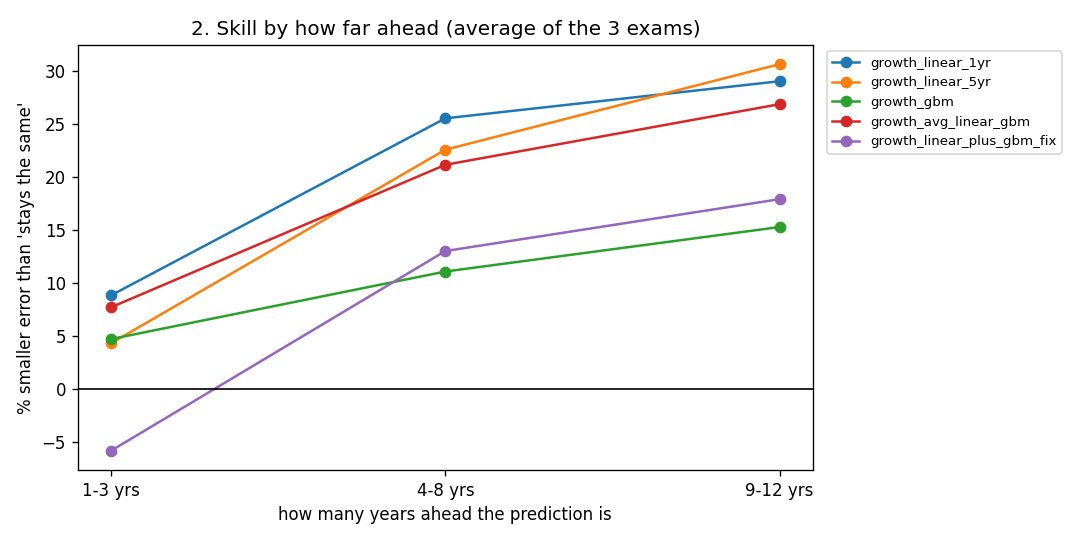

In [6]:
display(Image(R / "02_skill_by_years_ahead.png"))

## Graph 3: how much of the real change each model explains

**How to read it:** the fairest score. "Stays the same" scores 0 here, because it never predicts any change. A bar that seems missing has a value near 0 (its number is printed). A bar below 0 means the model's predicted changes were worse than predicting no change at all.

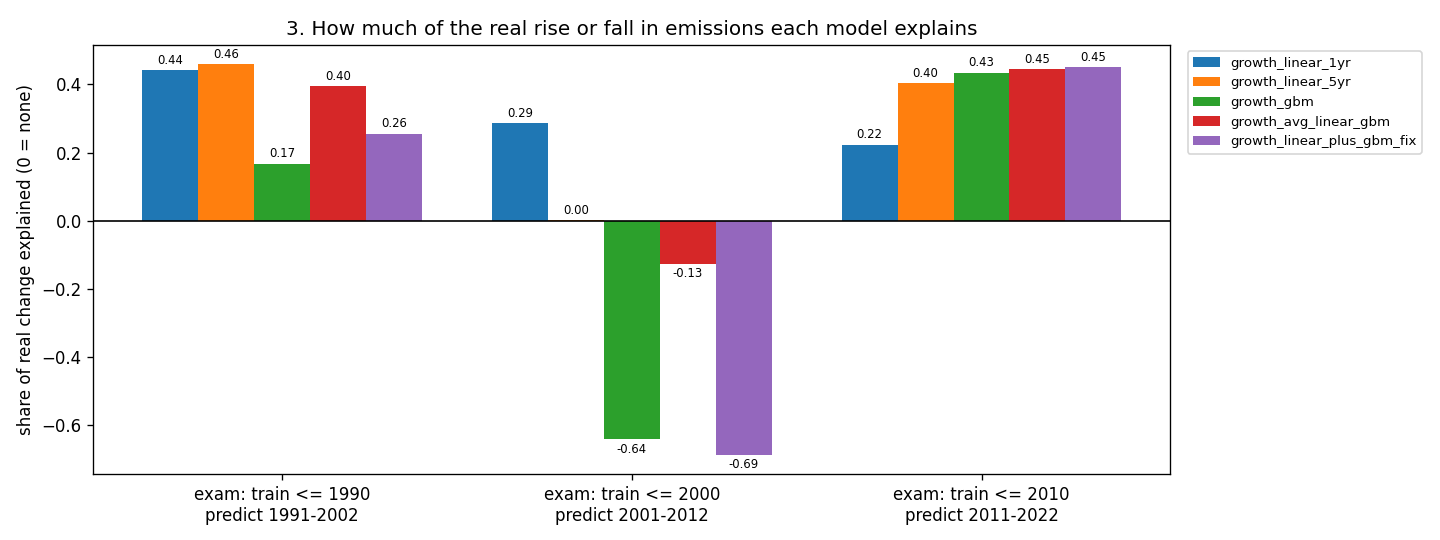

In [7]:
display(Image(R / "03_change_r2.png"))

## Graph 4: India, predicted from 2010

**How to read it:** black = India's real emissions. Grey dashed = "stays at the 2010 level". Coloured lines = each model's prediction for 2011-2022, made with data up to 2010 plus India's actual population and income changes.

**What to look for:** which coloured line follows the black line most closely.

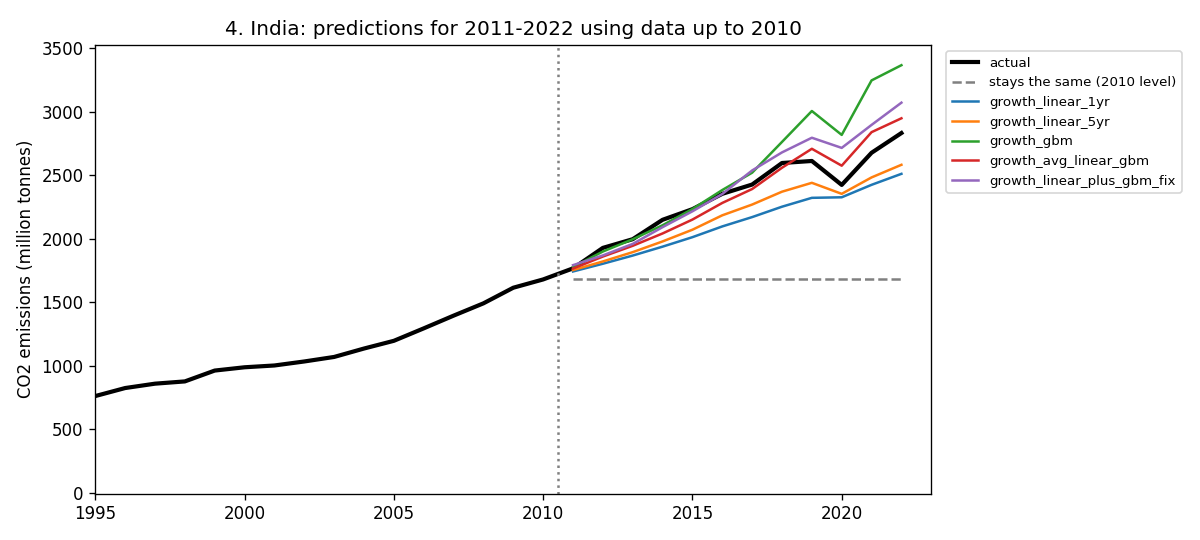

In [8]:
display(Image(R / "04_india_2011_2022.png"))

## Context: baselines and level models (exam 2011-2022 only)

`level_pop_income` predicts emissions directly from population and income. It explains differences *between* countries but ignores each country's own history, so it loses to "stays the same". `level_pop_income_energy` scores high mostly by the energy accounting rule.

In [9]:
other = res[~res.model.str.startswith("growth")][["model", "r2", "typical_pct_error", "skill_vs_stays_same_pct"]]
other.round(3)

,model,r2,typical_pct_error,skill_vs_stays_same_pct
0,baseline_stays_same,0.970,28.153,0.000
1,baseline_global_average,-0.025,475.018,-483.444
2,level_pop_income,0.862,93.260,-113.906
3,level_pop_income_energy,0.972,27.976,3.423


## Conclusions (generated from the numbers)

In [10]:
champ = summary["champion"]
c = growth[growth.model == champ]
wins = int((c.skill_vs_stays_same_pct > 0).sum())
lines = [
    f"- **Champion:** `{champ}`.",
    f"- It beats 'stays the same' in **{wins} of 3** exams, with an average skill of **{c.skill_vs_stays_same_pct.mean():.1f}%**.",
    f"- In the 2011-2022 exam it explains **{c[c.exam == 2010].change_r2.iloc[0]:.0%}** of the real change in emissions; 'stays the same' explains none.",
    "- Decision details: " + summary["reason"],
]
display(Markdown("\n".join(lines)))

- **Champion:** `growth_linear_5yr`.
- It beats 'stays the same' in **3 of 3** exams, with an average skill of **26.0%**.
- In the 2011-2022 exam it explains **40%** of the real change in emissions; 'stays the same' explains none.
- Decision details: No challenger passes the rule, so growth_linear_5yr stays. growth_gbm: -12.5 pts, wins 1/3 -> fails; growth_avg_linear_gbm: -2.1 pts, wins 1/3 -> fails; growth_linear_plus_gbm_fix: -11.1 pts, wins 1/3 -> fails